Nama Anggota Kelompok :
1. Adli Zhafir Prayata (03)
2. Azzam Habibillah Al Muzakki (08)
3. Sania Mirza (30)
4. Sinatrya Adjie Ramadhan (32)
5. Valentia Fibri Prastika (34)

In [ ]:

import pandas as pd

df = pd.read_csv('/content/ecommerce_sales_analytics_5000.csv')

print(df.head())

   order_id order_date  customer_id product_category region  quantity  \
0     10001   1/1/2022         1102           Beauty  South         7   
1     10002   1/2/2022         1435         Clothing  South         7   
2     10003   1/3/2022         1860           Beauty   East         3   
3     10004   1/4/2022         1270      Electronics   West         5   
4     10005   1/5/2022         1106         Clothing   West         5   

   unit_price  discount payment_method  delivery_days  customer_rating  \
0      373.65      0.28         Wallet             10              4.7   
1       47.74      0.09           Card              6              3.9   
2      311.28      0.31            COD              6              2.5   
3      524.47      0.02         Wallet              6              1.6   
4      139.87      0.33         Wallet              4              4.9   

   revenue  
0  1883.20  
1   304.10  
2   644.35  
3  2569.90  
4   468.56  


### Memuat Dataset

Pada tahap pertama, dilakukan proses pemuatan dataset menggunakan library Pandas. Dataset yang digunakan adalah `ecommerce_sales_analytics_5000.csv` yang berisi 5.000 data transaksi e-commerce.

Proses ini bertujuan untuk membaca file CSV dan menyimpannya ke dalam variabel `df` agar dapat diolah dan dianalisis menggunakan Python.

Perintah `df.head()` digunakan untuk menampilkan 5 baris pertama dari dataset sehingga kita dapat melihat struktur, nama kolom, serta contoh isi data sebelum melakukan proses analisis lebih lanjut.

In [ ]:

# Memeriksa informasi dataset
print("Informasi Dataset:")
df.info()

# Memeriksa data kosong
print("\nJumlah Missing Value:")
print(df.isnull().sum())

# Memeriksa data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

# Memeriksa duplikasi ID transaksi
print("\nJumlah Order ID Duplikat:")
print(df['order_id'].duplicated().sum())


Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB

Jumlah Missing Value:
order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity           

### Pemeriksaan Kondisi Dataset

Pada tahap ini, dilakukan pemeriksaan awal terhadap kondisi dataset menggunakan library Pandas. Pemeriksaan bertujuan untuk mengetahui kelengkapan data, tipe data pada setiap kolom, serta memastikan tidak terdapat data yang kosong maupun duplikat.

Beberapa pemeriksaan yang dilakukan meliputi:

1. `df.info()` digunakan untuk menampilkan informasi dataset, seperti jumlah baris, jumlah kolom, tipe data, dan jumlah data yang terisi pada setiap kolom.
2. `df.isnull().sum()` digunakan untuk menghitung jumlah nilai kosong (missing value) pada setiap kolom.
3. `df.duplicated().sum()` digunakan untuk menghitung jumlah baris yang memiliki data duplikat.
4. `df['order_id'].duplicated().sum()` digunakan untuk memeriksa apakah terdapat ID transaksi yang digunakan lebih dari satu kali.

Hasil pemeriksaan menunjukkan bahwa dataset memiliki 5.000 baris dan 12 kolom, tidak memiliki missing value, tidak ditemukan baris duplikat, serta tidak terdapat ID transaksi yang berulang.

In [ ]:

# Mengubah tipe data order_date menjadi datetime
df['order_date'] = pd.to_datetime(
    df['order_date'],
    format='%m/%d/%Y',
    errors='coerce'
)

# Memeriksa tipe data setelah perubahan
print(df['order_date'].dtype)

# Memeriksa tanggal yang tidak valid
print("Tanggal tidak valid:", df['order_date'].isnull().sum())


datetime64[ns]
Tanggal tidak valid: 0


### Mengubah Tipe Data Tanggal

Pada tahap ini, dilakukan perubahan tipe data pada kolom `order_date` dari `object` menjadi `datetime` menggunakan fungsi `pd.to_datetime()`.

Proses ini bertujuan agar data tanggal dapat dikenali oleh Python sebagai format tanggal sehingga bisa digunakan untuk analisis berdasarkan waktu, seperti pengelompokan transaksi per bulan atau tahun.

Beberapa bagian kode yang digunakan:

1. `pd.to_datetime()` digunakan untuk mengubah data menjadi format tanggal.
2. `format='%m/%d/%Y'` menunjukkan susunan format tanggal, yaitu bulan, hari, dan tahun.
3. `errors='coerce'` digunakan untuk mengubah tanggal yang tidak valid menjadi nilai kosong (`NaT`).
4. `.dtype` digunakan untuk memeriksa tipe data setelah konversi.
5. `.isnull().sum()` digunakan untuk menghitung jumlah tanggal yang tidak valid setelah proses konversi.

Hasil pemeriksaan menunjukkan bahwa tipe data `order_date` berhasil berubah menjadi `datetime64[ns]` dan tidak ditemukan tanggal yang tidak valid. Dengan demikian, kolom tanggal sudah siap digunakan untuk analisis tren penjualan berdasarkan periode waktu.

In [ ]:

# Menghapus data duplikat jika ditemukan
df = df.drop_duplicates()

# Menyimpan dataset hasil cleaning
df.to_csv('ecommerce_sales_clean.csv', index=False)

print("Data Cleaning Selesai!")
print("Jumlah Data Akhir:", len(df))


Data Cleaning Selesai!
Jumlah Data Akhir: 5000


### Menghapus Duplikasi dan Menyimpan Dataset

Pada tahap ini, dilakukan penghapusan data duplikat dan penyimpanan dataset yang telah melalui proses Data Cleaning.

Beberapa perintah yang digunakan:

1. `df.drop_duplicates()` digunakan untuk menghapus baris data yang memiliki isi duplikat agar tidak terjadi pengulangan data.
2. `df.to_csv()` digunakan untuk menyimpan dataset yang telah dibersihkan ke dalam file CSV baru dengan nama `ecommerce_sales_clean.csv`.
3. `index=False` digunakan agar nomor indeks DataFrame tidak ikut disimpan sebagai kolom tambahan.
4. `len(df)` digunakan untuk menghitung jumlah baris data setelah proses pembersihan selesai.

Hasil proses menunjukkan bahwa Data Cleaning berhasil dilakukan dengan jumlah akhir sebanyak 5.000 baris. Tidak ada data yang terhapus karena sebelumnya tidak ditemukan duplikasi.

Dengan demikian, dataset hasil pembersihan telah berhasil disimpan dan siap digunakan untuk tahap analisis selanjutnya.

### Validasi Data

Setelah proses Data Cleaning selesai, tahap selanjutnya adalah melakukan validasi data. Validasi dilakukan untuk memastikan bahwa nilai-nilai dalam dataset memiliki rentang yang wajar dan tidak terdapat kesalahan input.

Pemeriksaan diawali dengan melihat ringkasan statistik deskriptif untuk mengetahui karakteristik dasar dari setiap kolom numerik dalam dataset.

In [ ]:

# Memeriksa statistik deskriptif
print("Statistik Deskriptif:")
print(df.describe())


Statistik Deskriptif:
           order_id           order_date  customer_id     quantity  \
count   5000.000000                 5000  5000.000000  5000.000000   
mean   12500.500000  2028-11-04 12:00:00  1505.701200     4.044800   
min    10001.000000  2022-01-01 00:00:00  1000.000000     1.000000   
25%    11250.750000  2025-06-03 18:00:00  1253.000000     2.000000   
50%    12500.500000  2028-11-04 12:00:00  1510.000000     4.000000   
75%    13750.250000  2032-04-07 06:00:00  1761.000000     6.000000   
max    15000.000000  2035-09-09 00:00:00  1999.000000     7.000000   
std     1443.520003                  NaN   290.836902     2.020398   

        unit_price     discount  delivery_days  customer_rating      revenue  
count  5000.000000  5000.000000    5000.000000      5000.000000  5000.000000  
mean    308.418774     0.179984       6.118800         2.973980  1021.955148  
min      15.150000     0.000000       1.000000         1.000000    11.210000  
25%     161.895000     0.090000

**Penjelasan Kode:**

Perintah `df.describe()` digunakan untuk menampilkan ringkasan statistik deskriptif dari seluruh kolom numerik dalam dataset.

Informasi yang ditampilkan meliputi:

1. Count: Jumlah data.
2. Mean: Nilai rata-rata.
3. Std: Standar deviasi.
4. Min: Nilai terkecil.
5. 25%: Kuartil pertama (Q1).
6. 50%: Nilai tengah atau median (Q2).
7. 75%: Kuartil ketiga (Q3).
8. Max: Nilai terbesar.

Hasil ini membantu mengetahui karakteristik awal dan persebaran nilai dalam dataset.

### Pemeriksaan Rentang Nilai

Pemeriksaan rentang nilai dilakukan untuk mengetahui nilai minimum dan maksimum pada setiap kolom numerik yang berkaitan dengan transaksi penjualan.

Tujuannya adalah untuk menemukan kemungkinan nilai yang tidak wajar, seperti jumlah barang, harga produk, atau pendapatan yang bernilai negatif.

In [ ]:

# Memeriksa nilai minimum dan maksimum
kolom_numerik = [
    'quantity',
    'unit_price',
    'discount',
    'delivery_days',
    'customer_rating',
    'revenue'
]

for kolom in kolom_numerik:
    print(
        kolom,
        "| Minimum:", df[kolom].min(),
        "| Maksimum:", df[kolom].max()
    )


quantity | Minimum: 1 | Maksimum: 7
unit_price | Minimum: 15.15 | Maksimum: 599.96
discount | Minimum: 0.0 | Maksimum: 0.35
delivery_days | Minimum: 1 | Maksimum: 11
customer_rating | Minimum: 1.0 | Maksimum: 5.0
revenue | Minimum: 11.21 | Maksimum: 4119.33


**Penjelasan Kode:**

Kode ini digunakan untuk memeriksa nilai terkecil dan terbesar dari beberapa kolom numerik dalam dataset.

- `kolom_numerik` digunakan untuk menyimpan daftar nama kolom yang akan diperiksa.
- `for kolom in kolom_numerik` digunakan untuk melakukan pemeriksaan berulang pada setiap kolom.
- `.min()` digunakan untuk mencari nilai minimum.
- `.max()` digunakan untuk mencari nilai maksimum.

Hasil pemeriksaan dapat membantu mengidentifikasi nilai yang berpotensi tidak wajar dan perlu diperiksa lebih lanjut.

### Pemeriksaan Rentang Tanggal dan Kategori

Selanjutnya, dilakukan pemeriksaan terhadap rentang tanggal transaksi dan kategori produk yang tersedia dalam dataset.

Pemeriksaan ini bertujuan untuk mengetahui periode transaksi paling awal hingga paling akhir serta mengidentifikasi seluruh kategori produk yang akan digunakan dalam analisis penjualan.

In [ ]:

# Memeriksa rentang tanggal
print("Rentang Tanggal:")
print("Tanggal Awal:", df['order_date'].min())
print("Tanggal Akhir:", df['order_date'].max())

# Memeriksa kategori produk
print("\nKategori Produk:")
print(df['product_category'].unique())


Rentang Tanggal:
Tanggal Awal: 2022-01-01 00:00:00
Tanggal Akhir: 2035-09-09 00:00:00

Kategori Produk:
['Beauty' 'Clothing' 'Electronics' 'Home']


**Penjelasan Kode:**

Kode ini digunakan untuk mengetahui periode transaksi dan kategori produk yang terdapat dalam dataset.

- `df['order_date'].min()` digunakan untuk mengetahui tanggal transaksi paling awal.
- `df['order_date'].max()` digunakan untuk mengetahui tanggal transaksi paling akhir.
- `df['product_category'].unique()` digunakan untuk menampilkan seluruh kategori produk tanpa pengulangan.

Informasi ini nantinya dapat digunakan untuk menentukan periode analisis dan membandingkan performa penjualan setiap kategori produk.

In [ ]:

# Menentukan kolom numerik yang akan dianalisis
kolom_analisis = [
    'quantity',
    'unit_price',
    'discount',
    'delivery_days',
    'customer_rating',
    'revenue'
]

# Menghitung statistik deskriptif
statistik = df[kolom_analisis].describe()

print("Statistik Deskriptif:")
print(statistik)


Statistik Deskriptif:
          quantity   unit_price     discount  delivery_days  customer_rating  \
count  5000.000000  5000.000000  5000.000000    5000.000000      5000.000000   
mean      4.044800   308.418774     0.179984       6.118800         2.973980   
std       2.020398   169.259369     0.101404       3.153264         1.157722   
min       1.000000    15.150000     0.000000       1.000000         1.000000   
25%       2.000000   161.895000     0.090000       3.000000         2.000000   
50%       4.000000   309.890000     0.180000       6.000000         3.000000   
75%       6.000000   455.557500     0.270000       9.000000         4.000000   
max       7.000000   599.960000     0.350000      11.000000         5.000000   

           revenue  
count  5000.000000  
mean   1021.955148  
std     825.584219  
min      11.210000  
25%     354.527500  
50%     796.650000  
75%    1515.690000  
max    4119.330000  


### Penjelasan Statistik Deskriptif

Code tersebut menggunakan fungsi `describe()` dari Pandas untuk menghitung statistik dasar dari setiap kolom numerik.

Berikut beberapa informasi yang dihasilkan:

- **Count:** Jumlah data yang tersedia.
- **Mean:** Nilai rata-rata.
- **Std:** Standar deviasi atau tingkat penyebaran data.
- **Min:** Nilai terkecil.
- **25%:** Kuartil pertama (Q1).
- **50%:** Median atau nilai tengah.
- **75%:** Kuartil ketiga (Q3).
- **Max:** Nilai terbesar.

Hasil perhitungan ini digunakan sebagai dasar untuk memahami kondisi data sebelum membuat visualisasi.

In [ ]:

# Menghitung statistik tambahan
hasil_statistik = []

for kolom in kolom_analisis:
    q1 = df[kolom].quantile(0.25)
    q3 = df[kolom].quantile(0.75)

    hasil_statistik.append({
        'Kolom': kolom,
        'Mean': df[kolom].mean(),
        'Median': df[kolom].median(),
        'Modus': df[kolom].mode().iloc[0],
        'Range': df[kolom].max() - df[kolom].min(),
        'Varians': df[kolom].var(),
        'Standar Deviasi': df[kolom].std(),
        'IQR': q3 - q1
    })

# Menampilkan hasil dalam bentuk tabel
tabel_statistik = pd.DataFrame(hasil_statistik)

print("Hasil Perhitungan Statistik:")
display(tabel_statistik)


Hasil Perhitungan Statistik:


,Kolom,Mean,Median,Modus,Range,Varians,Standar Deviasi,IQR
0,quantity,4.044800,4.00,7.00,6.00,4.082009,2.020398,4.0000
1,unit_price,308.418774,309.89,124.05,584.81,28648.733946,169.259369,293.6625
2,discount,0.179984,0.18,0.25,0.35,0.010283,0.101404,0.1800
3,delivery_days,6.118800,6.00,10.00,10.00,9.943075,3.153264,6.0000
4,customer_rating,2.973980,3.00,2.20,4.00,1.340321,1.157722,2.0000
5,revenue,1021.955148,796.65,32.00,4108.12,681589.302978,825.584219,1161.1625


### Penjelasan Hasil Perhitungan Statistik

Code tersebut menghitung beberapa ukuran statistik untuk setiap kolom numerik yang telah dipilih.

- `mean()` digunakan untuk menghitung rata-rata.
- `median()` digunakan untuk mencari nilai tengah.
- `mode()` digunakan untuk mencari nilai yang paling sering muncul.
- `max() - min()` digunakan untuk menghitung range.
- `var()` digunakan untuk menghitung varians.
- `std()` digunakan untuk menghitung standar deviasi.
- `quantile()` digunakan untuk menentukan nilai kuartil.
- **IQR** dihitung dari selisih Q3 dan Q1.

Hasilnya ditampilkan dalam bentuk tabel agar lebih mudah dibaca dan dibandingkan.

### Persiapan Library Visualisasi

Sebelum membuat grafik, kita perlu mengimpor library Matplotlib dan Seaborn. Matplotlib digunakan untuk membuat dan mengatur tampilan grafik, sedangkan Seaborn membantu menghasilkan visualisasi data dengan tampilan yang lebih informatif.

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan grafik
sns.set_theme(style="whitegrid")


### Penjelasan Persiapan Library

- `matplotlib.pyplot` digunakan untuk membuat grafik dan mengatur elemen visualisasi.
- `seaborn` digunakan untuk membantu membuat grafik statistik.
- `sns.set_theme(style="whitegrid")` digunakan untuk mengatur tampilan grafik agar memiliki latar belakang dengan garis bantu sehingga data lebih mudah dibaca.

### Visualisasi Bar Chart

Bar Chart digunakan untuk membandingkan total pendapatan berdasarkan kategori produk. Pada grafik ini, data `revenue` akan dikelompokkan berdasarkan `product_category`, kemudian dijumlahkan untuk mengetahui total pendapatan dari setiap kategori produk.

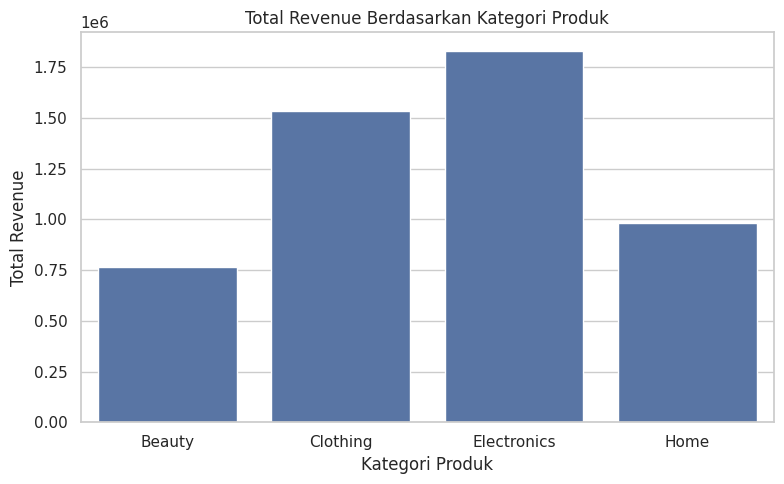

In [ ]:

# Menghitung total pendapatan setiap kategori produk
revenue_kategori = df.groupby('product_category')['revenue'].sum()

# Membuat Bar Chart
plt.figure(figsize=(8, 5))
sns.barplot(
    x=revenue_kategori.index,
    y=revenue_kategori.values
)

plt.title('Total Revenue Berdasarkan Kategori Produk')
plt.xlabel('Kategori Produk')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()


### Penjelasan Bar Chart

Code tersebut menggunakan `groupby()` untuk mengelompokkan data berdasarkan kategori produk. Fungsi `sum()` digunakan untuk menjumlahkan seluruh pendapatan pada setiap kategori.

Selanjutnya, `sns.barplot()` digunakan untuk menampilkan hasil pengelompokan dalam bentuk grafik batang. Grafik ini membantu membandingkan total pendapatan dari setiap kategori produk.

### Visualisasi Line Chart

Line Chart digunakan untuk melihat perubahan total pendapatan berdasarkan waktu. Pada grafik ini, data penjualan akan dikelompokkan berdasarkan bulan, kemudian total pendapatannya dijumlahkan untuk mengetahui perkembangan pendapatan dari waktu ke waktu.

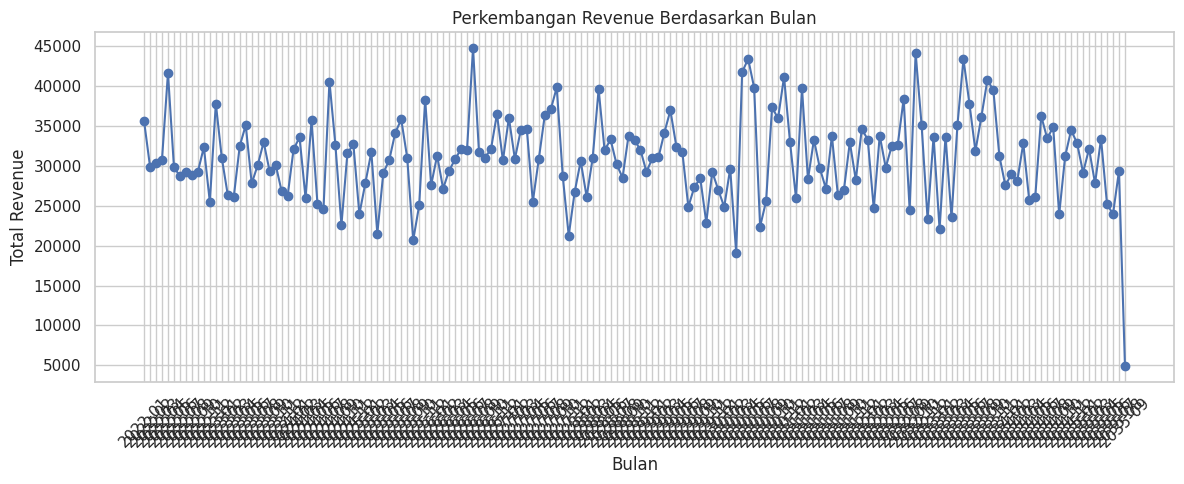

In [ ]:

# Mengelompokkan revenue berdasarkan bulan
revenue_bulanan = df.groupby(
    df['order_date'].dt.to_period('M')
)['revenue'].sum()

# Membuat Line Chart
plt.figure(figsize=(12, 5))
plt.plot(
    revenue_bulanan.index.astype(str),
    revenue_bulanan.values,
    marker='o'
)

plt.title('Perkembangan Revenue Berdasarkan Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Penjelasan Line Chart

Code tersebut menggunakan `groupby()` untuk mengelompokkan data berdasarkan bulan dari kolom `order_date`. Fungsi `sum()` digunakan untuk menghitung total pendapatan pada setiap bulan.

Selanjutnya, `plt.plot()` digunakan untuk membuat grafik garis yang menunjukkan perubahan pendapatan dari bulan ke bulan. Parameter `marker='o'` digunakan untuk menampilkan titik pada setiap data agar lebih mudah diamati.

### Visualisasi Scatter Plot

Scatter Plot digunakan untuk melihat hubungan antara jumlah produk yang dibeli (`quantity`) dengan pendapatan (`revenue`). Setiap titik pada grafik mewakili satu transaksi. Melalui grafik ini, kita dapat mengamati apakah jumlah produk yang dibeli memiliki hubungan dengan besar pendapatan yang diperoleh.

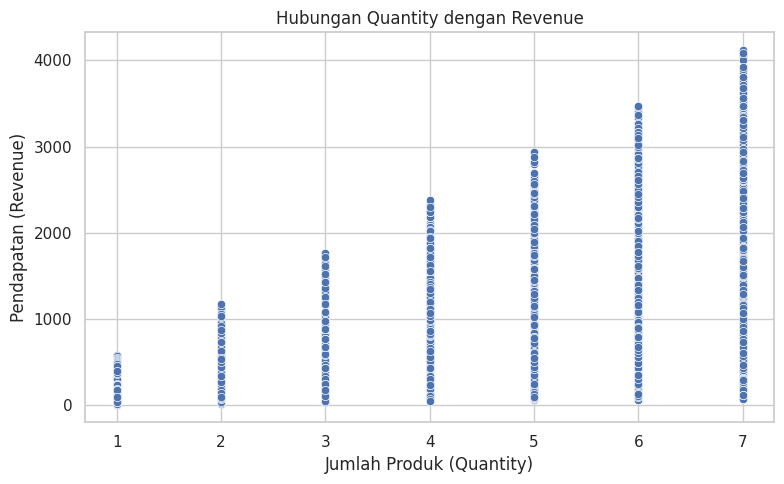

In [ ]:

# Membuat Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='quantity',
    y='revenue'
)

plt.title('Hubungan Quantity dengan Revenue')
plt.xlabel('Jumlah Produk (Quantity)')
plt.ylabel('Pendapatan (Revenue)')
plt.tight_layout()
plt.show()


### Penjelasan Scatter Plot

Code tersebut menggunakan `sns.scatterplot()` dari Seaborn untuk menampilkan hubungan antara dua kolom numerik.

- `data=df` menentukan dataset yang digunakan.
- `x='quantity'` menentukan variabel jumlah produk pada sumbu horizontal.
- `y='revenue'` menentukan variabel pendapatan pada sumbu vertikal.

Setiap titik menunjukkan satu transaksi. Pola persebaran titik dapat membantu mengetahui apakah terdapat hubungan antara jumlah produk yang dibeli dengan pendapatan yang diperoleh.

### Visualisasi Histogram

Histogram digunakan untuk mengetahui distribusi frekuensi pendapatan dalam dataset. Grafik ini menampilkan seberapa sering nilai pendapatan muncul pada rentang tertentu, sehingga kita dapat memahami pola penyebaran pendapatan dari seluruh transaksi.

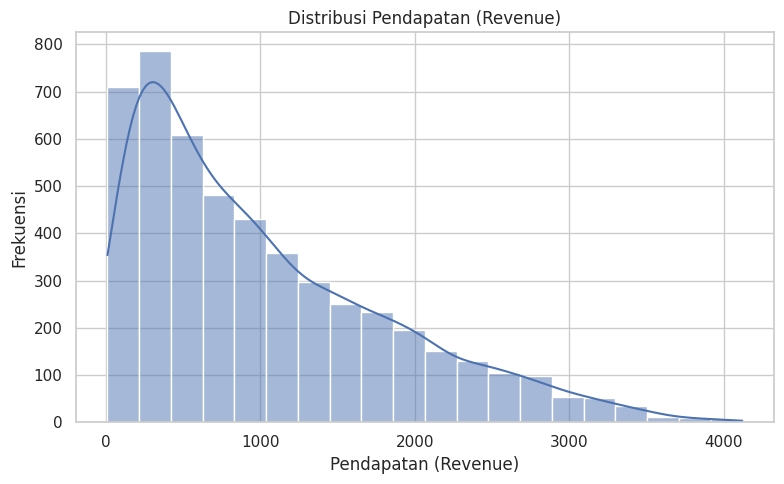

In [ ]:

# Membuat Histogram Revenue
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='revenue',
    bins=20,
    kde=True
)

plt.title('Distribusi Pendapatan (Revenue)')
plt.xlabel('Pendapatan (Revenue)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()


### Penjelasan Histogram

Code tersebut menggunakan `sns.histplot()` dari Seaborn untuk menampilkan distribusi data pendapatan.

- `data=df` menentukan dataset yang digunakan.
- `x='revenue'` menentukan kolom pendapatan yang dianalisis.
- `bins=20` membagi rentang pendapatan menjadi 20 kelompok.
- `kde=True` menambahkan garis distribusi untuk membantu melihat pola penyebaran data.

Sumbu horizontal menunjukkan rentang pendapatan, sedangkan sumbu vertikal menunjukkan frekuensi atau jumlah transaksi pada setiap rentang.

### Insight Histogram

Berdasarkan Histogram Distribusi Pendapatan (Revenue), sebagian besar transaksi memiliki pendapatan pada rentang sekitar 200 hingga 1.000. Semakin tinggi nilai pendapatan, frekuensi transaksi cenderung semakin menurun. Grafik ini menunjukkan bahwa distribusi pendapatan memiliki pola miring ke kanan (*right-skewed*), karena terdapat sejumlah kecil transaksi dengan pendapatan yang jauh lebih tinggi dibandingkan transaksi lainnya.

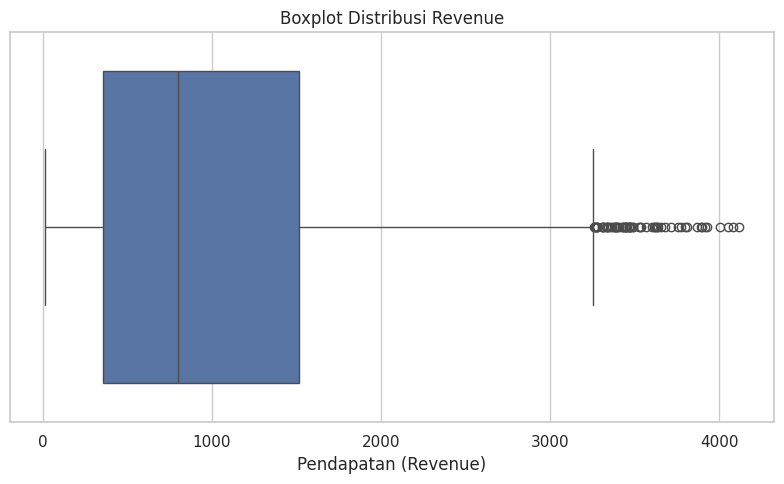

In [ ]:

# Membuat Boxplot Revenue
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='revenue'
)

plt.title('Boxplot Distribusi Revenue')
plt.xlabel('Pendapatan (Revenue)')
plt.tight_layout()
plt.show()


### Penjelasan Boxplot

Code tersebut menggunakan `sns.boxplot()` dari Seaborn untuk menampilkan penyebaran data pendapatan.

- `data=df` menentukan dataset yang digunakan.
- `x='revenue'` menentukan kolom pendapatan yang dianalisis.
- `plt.figure(figsize=(8, 5))` mengatur ukuran grafik.
- `plt.title()` memberikan judul grafik.
- `plt.xlabel()` memberikan nama pada sumbu horizontal.

Titik yang berada di luar batas whisker dapat menunjukkan adanya potensi outlier. Nilai tersebut perlu diperiksa lebih lanjut sebelum menentukan apakah termasuk data yang tidak wajar.

### Deteksi Outlier Menggunakan Metode IQR

Interquartile Range (IQR) merupakan metode yang digunakan untuk mendeteksi potensi outlier berdasarkan jarak antara kuartil pertama (Q1) dan kuartil ketiga (Q3).

Batas bawah dan batas atas dihitung menggunakan rumus:

- IQR = Q3 - Q1
- Batas bawah = Q1 - (1,5 × IQR)
- Batas atas = Q3 + (1,5 × IQR)

Data yang memiliki nilai di bawah batas bawah atau di atas batas atas akan dikategorikan sebagai potensi outlier.

In [ ]:

# Menghitung nilai Q1 dan Q3
Q1 = df['revenue'].quantile(0.25)
Q3 = df['revenue'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas outlier
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

# Mengidentifikasi outlier
outlier = df[
    (df['revenue'] < batas_bawah) |
    (df['revenue'] > batas_atas)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)
print("Jumlah Potensi Outlier:", len(outlier))


Q1: 354.5275
Q3: 1515.69
IQR: 1161.1625000000001
Batas Bawah: -1387.2162500000002
Batas Atas: 3257.43375
Jumlah Potensi Outlier: 67


### Penjelasan Perhitungan Outlier

Code tersebut menghitung nilai Q1, Q3, dan IQR dari kolom `revenue`. Selanjutnya, nilai tersebut digunakan untuk menentukan batas bawah dan batas atas menggunakan metode IQR.

Data yang berada di luar kedua batas tersebut dikumpulkan ke dalam variabel `outlier`. Fungsi `len()` digunakan untuk menghitung jumlah data yang teridentifikasi sebagai potensi outlier.

### Pemeriksaan Data Outlier

Pemeriksaan ini dilakukan untuk melihat contoh transaksi yang teridentifikasi sebagai potensi outlier. Dengan memeriksa nilai pendapatan dan jumlah produk pada transaksi tersebut, kita dapat memperoleh gambaran mengenai kemungkinan penyebab munculnya nilai yang berbeda dari sebagian besar data.

In [ ]:

# Menampilkan beberapa data outlier
print("Contoh Data Potensi Outlier:")
display(outlier[['order_id', 'product_category', 'quantity', 'unit_price', 'discount', 'revenue']].head(10))


Contoh Data Potensi Outlier:


,order_id,product_category,quantity,unit_price,discount,revenue
39,10040,Home,7,584.36,0.11,3640.56
69,10070,Beauty,7,567.75,0.16,3338.37
102,10103,Clothing,6,586.65,0.02,3449.50
126,10127,Clothing,7,506.18,0.02,3472.39
157,10158,Electronics,7,571.07,0.02,3917.54
178,10179,Electronics,7,598.63,0.19,3394.23
241,10242,Electronics,7,550.20,0.11,3427.75
256,10257,Home,7,507.39,0.03,3445.18
321,10322,Electronics,7,585.43,0.05,3893.11
369,10370,Beauty,7,529.25,0.02,3630.66


### Penjelasan Pemeriksaan Data Outlier

Code tersebut menampilkan maksimal 10 baris data yang teridentifikasi sebagai potensi outlier. Informasi yang ditampilkan meliputi ID transaksi, kategori produk, jumlah produk, harga satuan, diskon, dan pendapatan.

Data tersebut digunakan untuk membantu memahami karakteristik transaksi yang memiliki pendapatan jauh lebih tinggi dibandingkan transaksi lainnya.

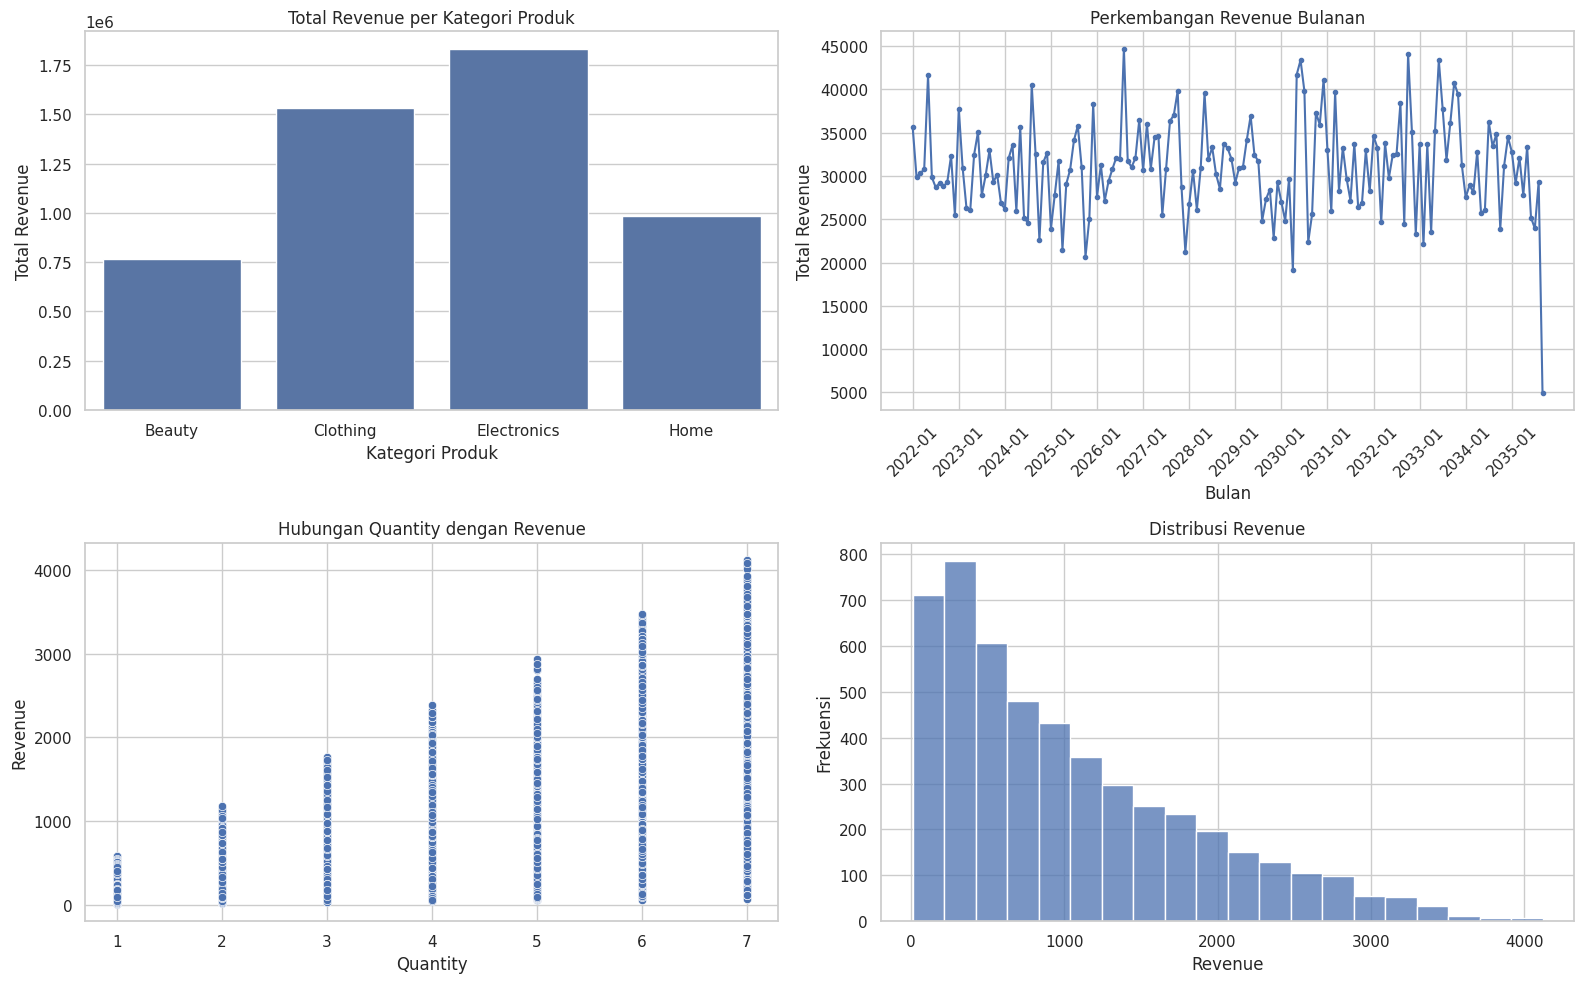

In [ ]:

# Menghitung total revenue berdasarkan kategori produk
revenue_kategori = df.groupby('product_category')['revenue'].sum()

# Menghitung total revenue berdasarkan bulan
revenue_bulanan = df.groupby(
    df['order_date'].dt.to_period('M')
)['revenue'].sum()

# Membuat dashboard dengan 4 grafik
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Grafik 1: Bar Chart
sns.barplot(
    x=revenue_kategori.index,
    y=revenue_kategori.values,
    ax=axes[0, 0]
)
axes[0, 0].set_title('Total Revenue per Kategori Produk')
axes[0, 0].set_xlabel('Kategori Produk')
axes[0, 0].set_ylabel('Total Revenue')


# Grafik 2: Line Chart
axes[0, 1].plot(
    revenue_bulanan.index.astype(str),
    revenue_bulanan.values,
    marker='o',
    markersize=3
)

axes[0, 1].set_title('Perkembangan Revenue Bulanan')
axes[0, 1].set_xlabel('Bulan')
axes[0, 1].set_ylabel('Total Revenue')

# Menampilkan label setiap 12 bulan
axes[0, 1].set_xticks(
    range(0, len(revenue_bulanan), 12)
)

axes[0, 1].set_xticklabels(
    revenue_bulanan.index.astype(str)[::12],
    rotation=45
)

# Grafik 3: Scatter Plot
sns.scatterplot(
    data=df,
    x='quantity',
    y='revenue',
    ax=axes[1, 0]
)
axes[1, 0].set_title('Hubungan Quantity dengan Revenue')
axes[1, 0].set_xlabel('Quantity')
axes[1, 0].set_ylabel('Revenue')

# Grafik 4: Histogram
sns.histplot(
    data=df,
    x='revenue',
    bins=20,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Distribusi Revenue')
axes[1, 1].set_xlabel('Revenue')
axes[1, 1].set_ylabel('Frekuensi')

# Mengatur tampilan dashboard
plt.tight_layout()
plt.show()


### Penjelasan Dashboard Visualisasi

Code tersebut menggabungkan empat grafik menggunakan `plt.subplots(2, 2)`, sehingga dashboard memiliki dua baris dan dua kolom.

Sebelum membuat grafik, fungsi `groupby()` digunakan untuk mengelompokkan pendapatan berdasarkan kategori produk dan bulan. Selanjutnya, setiap grafik ditempatkan pada area yang berbeda menggunakan parameter `ax`.

Fungsi `plt.tight_layout()` digunakan untuk mengatur jarak antar grafik agar dashboard terlihat lebih rapi dan mudah dibaca.

## Rekomendasi Berdasarkan Hasil Analisis

Berdasarkan hasil analisis dataset penjualan e-commerce, terdapat beberapa hal yang dapat dijadikan bahan pertimbangan untuk meningkatkan kinerja penjualan.

Pertama, kategori Electronics memiliki total pendapatan tertinggi dibandingkan kategori produk lainnya. Oleh karena itu, perusahaan dapat mempertahankan ketersediaan produk Electronics dan mengembangkan strategi promosi yang sesuai. Sementara itu, kategori Beauty memiliki pendapatan terendah sehingga dapat diberikan perhatian lebih melalui program diskon atau promosi untuk meningkatkan minat pembelian.

Kedua, hasil Scatter Plot menunjukkan bahwa semakin banyak jumlah produk yang dibeli, pendapatan cenderung semakin tinggi. Berdasarkan hal tersebut, perusahaan dapat mempertimbangkan strategi paket pembelian atau penawaran khusus untuk mendorong pelanggan membeli lebih dari satu produk.

Ketiga, hasil Histogram menunjukkan bahwa sebagian besar transaksi memiliki pendapatan pada rentang yang relatif rendah. Perusahaan dapat mengembangkan strategi pemasaran untuk meningkatkan nilai pembelian pelanggan, misalnya melalui penawaran produk tambahan yang relevan.

Selain itu, analisis menggunakan metode IQR menemukan 67 transaksi yang berpotensi menjadi outlier. Transaksi tersebut perlu diperiksa lebih lanjut untuk memastikan bahwa nilai pendapatannya benar dan bukan disebabkan oleh kesalahan pencatatan.

Secara keseluruhan, perusahaan disarankan untuk mempertahankan performa kategori produk yang menghasilkan pendapatan tinggi, meningkatkan strategi pemasaran pada kategori dengan pendapatan rendah, serta melakukan pemantauan data penjualan secara berkala agar keputusan bisnis dapat dibuat berdasarkan informasi yang lebih akurat.